# Project 2.2 - Implementation report & presentation

Course: Multi-Modal Data Analysis (Semester II - 2026)

Course Code: COMP 1013

Student Name: Supun Lahiru Gayan Wijesooriya

Student ID: a1985949

Student Email: supun.wijesooriya@student.adelaide.edu.au

Program: Master of Data Science (Coursework)

Submitted on 05th of September, 2026

Adelaide, 5005 SA


# MM-IMDb Multimodal Fusion
### Project Implementation


This notebook implements multimodal multi-label movie genre classification using the MM-IMDb dataset.


Modalities:
1.   Movie poster images
2.   Plot-summary text



Target: Multi-label classification across 23 movie genres

The project will compare unimodal and multimodal fusion approaches using a common train/validation/test split.

This project investigates whether combining visual information from movie posters with textual information from plot summaries improves multi-label movie genre classification compared with using either modality independently.

The implementation begins with a final verification of the packaged MM-IMDb dataset. This is necessary because the Kaggle distribution stores the data in `metadata.npy` and `multimodal_imdb.hdf5` than as separate poster and metadata files.

The verification stage confirms the structure, alignment, quality and interpretation of the image, text and target data before any model training is performed.

## Preliminary Dataset Analysis Summary

An initial exploratory analysis was conducted on the Kaggle distribution of the MM-IMDb dataset before beginning the full project implementation. The dataset is provided in two packaged binary files: `metadata.npy` and `multimodal_imdb.hdf5`.

The analysis confirmed that the HDF5 file contains the movie-level modalities, target labels and several precomputed feature representations required for multimodal modelling.

The main HDF5 datasets identified were:


- `images` — movie poster tensors
- `sequences` — tokenised textual representations of movie plot summaries
- `genres` — multi-label genre targets containing 23 output dimensions
- `imdb_ids` — IMDb identifiers for individual movies
- `vgg_features` — 4096-dimensional precomputed visual features
- `features` — 300-dimensional feature representations
- `word_grams` and `three_grams` — additional text representations

*   decoding and assessing the plot sequences,
*   analysing the genre-label distribution and imbalance,
*   confirming the mapping between the 23 target dimensions and genre names,
*   reconstructing the stored poster tensors correctly,
*   checking IMDb identifier uniqueness.


Each of these movie-level datasets contains 25,959 samples. This provides initial evidence that the poster, text, identifier and genre-label data are aligned by movie index.

The `metadata.npy` file was found to contain supporting information for text processing rather than one metadata record per movie. Its contents include vocabulary mappings and a word-embedding lookup structure. This can be used with the tokenised plot sequences. So, the four top-level entries in this file should not be interpreted as four movie records.

A sampled quality assessment of 1,000 poster tensors identified **no non-finite arrays and no near-constant images**. This shows that there's no immediate evidence of corrupted visual samples. The stored poster tensors contain transformed pixel values, including negative values. This indicates that they have already undergone image preprocessing and must be use with another pretrained image encoder (or interpreted appropriately before visualisation).

The preliminary analysis indicates that MM-IMDb is suitable for the proposed multimodal multi-label classification task. It provides two distinct modalities—movie posters and plot information—together with 23-dimensional genre targets and several existing feature representations.

Before model development, the main implementation performs several final verification steps:

*   decoding and assessing the plot sequences,
*   analysing the genre-label distribution and imbalance,
*   confirming the mapping between the 23 target dimensions and genre names,
*   reconstructing the stored poster tensors correctly,
*   checking IMDb identifier uniqueness.

These checks form part of the data-quality and preprocessing stage of the final project.

# MM-IMDb Multimodal Fusion for Multi-Label Genre Classification

This project investigates whether combining visual information from movie posters with textual information from plot summaries improves multi-label movie genre classification compared with using either modality independently.

The implementation begins with a final verification of the packaged MM-IMDb dataset. This is necessary because the Kaggle distribution stores the data in `metadata.npy` and `multimodal_imdb.hdf5` rather than as separate poster and metadata files.

The verification stage confirms the structure, alignment, quality and interpretation of the image, text and target data before any model training is performed.

# 1. Environment and reproducibility

In [76]:
# 1. Environment and reproducibility

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py

from pathlib import Path

# Fixed random seed for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Random seed:", SEED)

Random seed: 42


In [77]:
# Mounting Google Drive

from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# Dataset paths

PROJECT_DIR = Path(
    "/content/drive/MyDrive/MMIMDb_Project"
)

DATA_DIR = PROJECT_DIR / "mmimdb_extracted"

METADATA_PATH = DATA_DIR / "metadata.npy"
HDF5_PATH = DATA_DIR / "multimodal_imdb.hdf5"

print("Metadata file exists:", METADATA_PATH.exists())
print("HDF5 file exists:", HDF5_PATH.exists())

Metadata file exists: True
HDF5 file exists: True


# 2. Load the packaged dataset

In [6]:
# 2. Load metadata and inspect HDF5 structure

metadata = np.load(
    METADATA_PATH,
    allow_pickle=True
).item()

print("Metadata keys:")
print(metadata.keys())

print("\nMetadata components:")
for key, value in metadata.items():
    try:
        print(
            f"{key}: type={type(value)}, "
            f"shape={np.shape(value)}"
        )
    except Exception:
        print(
            f"{key}: type={type(value)}"
        )

Metadata keys:
dict_keys(['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word'])

Metadata components:
lookup: type=<class 'numpy.ndarray'>, shape=(41611, 300)
vocab_size: type=<class 'int'>, shape=()
word_to_ix: type=<class 'dict'>, shape=()
ix_to_word: type=<class 'dict'>, shape=()


In [7]:
# Inspect the datasets stored inside the HDF5 file

with h5py.File(HDF5_PATH, "r") as h5_file:

    print("HDF5 datasets:\n")

    for key in h5_file.keys():

        dataset = h5_file[key]

        print(
            f"{key:<15} "
            f"shape={dataset.shape}, "
            f"dtype={dataset.dtype}"
        )

HDF5 datasets:

features        shape=(25959, 300), dtype=float32
genres          shape=(25959, 23), dtype=int32
images          shape=(25959, 3, 256, 160), dtype=int32
imdb_ids        shape=(25959,), dtype=|S7
sequences       shape=(25959,), dtype=object
three_grams     shape=(25959, 9946), dtype=float32
vgg_features    shape=(25959, 4096), dtype=float32
word_grams      shape=(25959, 13253), dtype=float32


# 3. Final Dataset Verification and Quality Assessment

In [8]:
# 3.1 Check sample counts across the movie-level datasets

with h5py.File(HDF5_PATH, "r") as h5_file:

    datasets_to_check = [
        "images",
        "genres",
        "imdb_ids",
        "sequences",
        "features",
        "vgg_features",
        "word_grams",
        "three_grams"
    ]

    sample_counts = {}

    for name in datasets_to_check:

        if name in h5_file:

            sample_counts[name] = (
                h5_file[name].shape[0]
            )

sample_counts_df = pd.DataFrame(
    sample_counts.items(),
    columns=[
        "Dataset",
        "Number of Samples"
    ]
)

display(sample_counts_df)

,Dataset,Number of Samples
0,images,25959
1,genres,25959
2,imdb_ids,25959
3,sequences,25959
4,features,25959
5,vgg_features,25959
6,word_grams,25959
7,three_grams,25959


In [9]:
unique_counts = set(
    sample_counts.values()
)

print(
    "Unique sample counts:",
    unique_counts
)

print(
    "All movie-level datasets aligned:",
    len(unique_counts) == 1
)

Unique sample counts: {25959}
All movie-level datasets aligned: True


### Sample Alignment

The movie-level datasets were checked to confirm that each modality and target representation contains the same number of samples. Consistent first-dimension sizes indicate that poster images, plot representations, IMDb identifiers and genre labels are aligned by movie index. This is essential for multimodal fusion because features from different modalities must correspond to the same observation.

In [14]:
# 3.2 Inspect tokenised plot summaries


with h5py.File(HDF5_PATH, "r") as h5_file:

    sequences = h5_file["sequences"]

    print("Sequences shape:", sequences.shape)

    print("\nFirst sequence:")
    print(sequences[0])

Sequences shape: (25959,)

First sequence:
[18186   418  5100     1  1562    40     7    37   112    18  1805   544
     1   923    18    94     5    10   317    14   481    11    13   418
  1534     3     2   254     9     8     4  3532   102     1     5  5100
     1    19    28   136     2 39133     6  1283   111    15     4    32
    14  3484  5095    31    25    70   752    20     2   428     1     9
  5067    15   733  1617     3    33  1116  5070 20742  2059     8     2
   239   110  1596     6   612   124     2  1977     6   423     4  3548
    20     2    53    19   636    16   588     1  5100    11    13   102
    15     2  2472   594   142  2707   115   494   247     3    27   209
   312     6   118   588    33    10   481     9   482     1     5  5100
   111   167    94     6    71    10   389  8610    22     4 25550  5161
    19   167    85     6 43459    14    14     5     6   493    30     4
  3782  2462    14    90    54     2  9143  7467     7  5222    17   594
   142  

In [15]:
# Inspect the vocabulary mapping

ix_to_word = metadata["ix_to_word"]

print("ix_to_word type:", type(ix_to_word))
print("Vocabulary entries:", len(ix_to_word))

print("\nFirst 10 vocabulary mappings:")

for i, item in enumerate(ix_to_word.items()):
    if i == 10:
        break

    print(item)

ix_to_word type: <class 'dict'>
Vocabulary entries: 69980

First 10 vocabulary mappings:
(0, '_UNK_')
(1, ',')
(2, 'the')
(3, '.')
(4, 'a')
(5, 'and')
(6, 'to')
(7, 'of')
(8, 'in')
(9, 'is')


In [16]:
# Decode tokenised plot summaries

def decode_sequence(sequence, ix_to_word):

    words = []

    for token_id in sequence:

        token_id = int(token_id)

        word = ix_to_word.get(
            token_id,
            "_UNK_"
        )

        words.append(word)

    text = " ".join(words)

    text = (
        text
        .replace(" ,", ",")
        .replace(" .", ".")
        .replace(" !", "!")
        .replace(" ?", "?")
        .replace(" ;", ";")
        .replace(" :", ":")
    )

    return text

In [17]:
# Display example decoded plot summaries

with h5py.File(HDF5_PATH, "r") as h5_file:

    sequences = h5_file["sequences"]

    for i in range(3):

        sequence = np.asarray(
            sequences[i]
        )

        decoded_plot = decode_sequence(
            sequence,
            ix_to_word
        )

        print(f"\nMovie {i}")
        print("-" * 80)
        print(decoded_plot[:1500])


Movie 0
--------------------------------------------------------------------------------
sardonic detective shane, thrown out of one town for bringing trouble, heads for home and his ex - partner ' s detective agency. the business is in a sad way, and shane, who has had the forethought to provide himself with a N - dollar commission from an old lady on the train, is welcomed with open arms. when pretty valerie purvis walks in the next day willing to pay over the odds to put a tail on the man who did her wrong, shane ' s way with the ladies looks like paying off yet again. but things start to go wrong when his partner is murdered, and shane himself comes home to find his apartment wrecked by a gentlemanly crook who comes back to apologise - - and to tell him a fascinating fairy - story about the fabled horn of roland that looks like not being so mythical after all. miss purvis wants protection. the police want answers. and all sorts of people want the ' french horn '... but shane is on

### Plot-Summary Verification

The `sequences` dataset contains tokenised movie plot summaries, while the `ix_to_word` dictionary in `metadata.npy` maps integer token identifiers back to vocabulary terms. Decoding sample sequences produced coherent and semantically meaningful movie-plot descriptions. This confirms that the stored sequences provide a valid textual modality for the multimodal classification task.

The vocabulary contains 69,980 entries. This provides sufficient coverage for reconstruction of the tokenised plots. These sequences can be used for subsequent text feature extraction and multimodal fusion.

In [18]:
# 3.3 Analyse multi-label genre targets


with h5py.File(HDF5_PATH, "r") as h5_file:

    genres = np.asarray(
        h5_file["genres"][:]
    )

print(
    "Genre matrix shape:",
    genres.shape
)

print(
    "Genre matrix dtype:",
    genres.dtype
)

print(
    "\nUnique values in genre matrix:",
    np.unique(genres)
)

print(
    "\nFirst five genre vectors:"
)

print(
    genres[:5]
)

Genre matrix shape: (25959, 23)
Genre matrix dtype: int32

Unique values in genre matrix: [0 1]

First five genre vectors:
[[1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1]
 [1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]
 [1 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1]
 [1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]
 [1 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]]


In [19]:
# Number of genre labels assigned to each movie

labels_per_movie = genres.sum(
    axis=1
)

print(
    "Minimum genres per movie:",
    labels_per_movie.min()
)

print(
    "Maximum genres per movie:",
    labels_per_movie.max()
)

print(
    "Mean genres per movie:",
    round(
        labels_per_movie.mean(),
        2
    )
)

print(
    "Median genres per movie:",
    np.median(
        labels_per_movie
    )
)

print(
    "Movies with zero genre labels:",
    np.sum(
        labels_per_movie == 0
    )
)

Minimum genres per movie: 1
Maximum genres per movie: 10
Mean genres per movie: 2.48
Median genres per movie: 2.0
Movies with zero genre labels: 0


In [20]:
# Frequency of each of the 23 genre targets

genre_frequency = genres.sum(
    axis=0
)

genre_frequency_df = pd.DataFrame({
    "Genre Index": np.arange(
        genres.shape[1]
    ),
    "Movie Count": genre_frequency
})

display(
    genre_frequency_df
)

,Genre Index,Movie Count
0,0,13967
1,1,8592
2,2,5364
3,3,5192
4,4,3838
5,5,3550
6,6,2710
7,7,2703
8,8,2082
9,9,2057


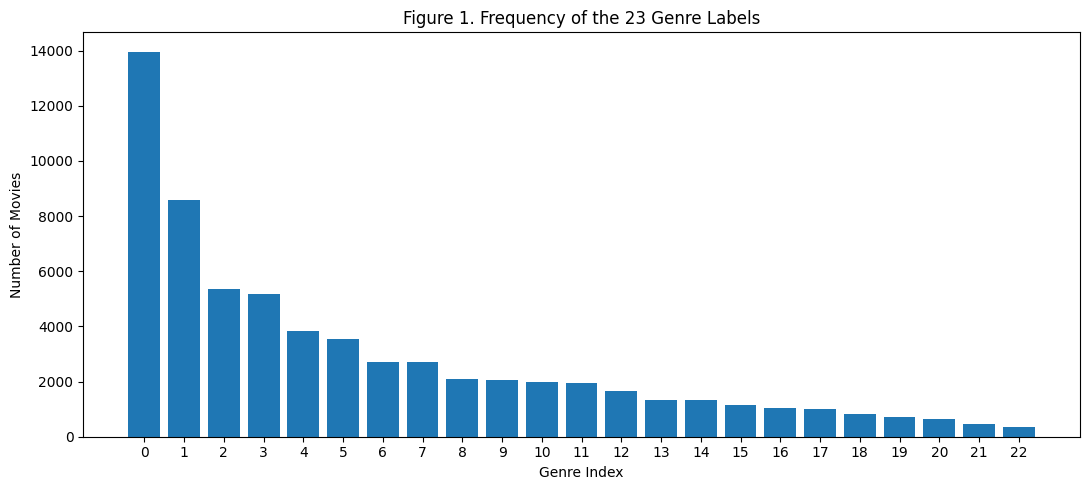

In [21]:
# Visualise genre-label frequencies

plt.figure(
    figsize=(11, 5)
)

plt.bar(
    genre_frequency_df[
        "Genre Index"
    ].astype(str),
    genre_frequency_df[
        "Movie Count"
    ]
)

plt.title(
    "Figure 1. Frequency of the 23 Genre Labels"
)

plt.xlabel(
    "Genre Index"
)

plt.ylabel(
    "Number of Movies"
)

plt.tight_layout()
plt.show()

### Multi-Label Genre Target Analysis

The target matrix contains 25,959 movies and 23 genre dimensions, with binary values of `0` and `1`. This confirms that the task is a multi-label classification problem. Every movie has at least one genre label while individual movies contain between 1 and 10 genres. The mean number of genres per movie is 2.48 and the median is 2.

The genre-frequency distribution is strongly imbalanced with several genre dimensions occurring more often than others. This imbalance will be considered during model evaluation by using multi-label metrics like macro-F1, micro-F1, precision, recall and Hamming loss rather than relying only on overall accuracy.

In [22]:
# 3.4 Confirm genre-label mapping


import json

with h5py.File(HDF5_PATH, "r") as h5_file:

    genre_dataset = h5_file[
        "genres"
    ]

    print(
        "Genre dataset attributes:"
    )

    for key, value in genre_dataset.attrs.items():
        print(
            key,
            ":",
            value
        )

Genre dataset attributes:
DIMENSION_LABELS : ['batch' 'classes']
target_names : ["Drama", "Comedy", "Romance", "Thriller", "Crime", "Action", "Adventure", "Horror", "Documentary", "Mystery", "Sci-Fi", "Fantasy", "Family", "Biography", "War", "History", "Music", "Animation", "Musical", "Western", "Sport", "Short", "Film-Noir"]


In [23]:
with h5py.File(HDF5_PATH, "r") as h5_file:

    genre_names = json.loads(
        h5_file[
            "genres"
        ].attrs[
            "target_names"
        ]
    )

print(
    "Number of genre names:",
    len(genre_names)
)

print(
    "\nGenre mapping:"
)

for index, genre in enumerate(
    genre_names
):

    print(
        f"{index:2d} -> {genre}"
    )

Number of genre names: 23

Genre mapping:
 0 -> Drama
 1 -> Comedy
 2 -> Romance
 3 -> Thriller
 4 -> Crime
 5 -> Action
 6 -> Adventure
 7 -> Horror
 8 -> Documentary
 9 -> Mystery
10 -> Sci-Fi
11 -> Fantasy
12 -> Family
13 -> Biography
14 -> War
15 -> History
16 -> Music
17 -> Animation
18 -> Musical
19 -> Western
20 -> Sport
21 -> Short
22 -> Film-Noir


In [24]:
genre_frequency_df = pd.DataFrame({
    "Genre": genre_names,
    "Movie Count": genre_frequency
})

genre_frequency_df = (
    genre_frequency_df
    .sort_values(
        "Movie Count",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

display(
    genre_frequency_df
)

,Genre,Movie Count
0,Drama,13967
1,Comedy,8592
2,Romance,5364
3,Thriller,5192
4,Crime,3838
5,Action,3550
6,Adventure,2710
7,Horror,2703
8,Documentary,2082
9,Mystery,2057


### Genre-Label Mapping

The HDF5 `genres` dataset stores the class names directly in its `target_names` attribute. This confirms the ordering of the 23 multi-label outputs, allowing each binary target column to be mapped reliably to its corresponding genre.

The resulting distribution shows substantial class imbalance. Common genres such as Drama and Comedy appear more frequently than rare genres such as Short and Film-Noir. This imbalance will be considered when interpreting class-specific performance and macro-averaged evaluation metrics.

In [26]:
# 3.5 Inspect stored poster tensors


with h5py.File(HDF5_PATH, "r") as h5_file:

    images = h5_file[
        "images"
    ]

    print(
        "Image dataset shape:",
        images.shape
    )

    sample_image = np.asarray(
        images[0]
    )

print(
    "Single image shape:",
    sample_image.shape
)

print(
    "Minimum value:",
    sample_image.min()
)

print(
    "Maximum value:",
    sample_image.max()
)

print(
    "Mean value:",
    round(
        sample_image.mean(),
        4
    )
)

print(
    "Standard deviation:",
    round(
        sample_image.std(),
        4
    )
)

Image dataset shape: (25959, 3, 256, 160)
Single image shape: (3, 256, 160)
Minimum value: -123
Maximum value: 138
Mean value: 44.1834
Standard deviation: 73.9877


In [27]:
# Examine the three stored image channels

for channel in range(
    sample_image.shape[0]
):

    print(
        f"Channel {channel}: "
        f"min={sample_image[channel].min():.2f}, "
        f"max={sample_image[channel].max():.2f}, "
        f"mean={sample_image[channel].mean():.2f}"
    )

Channel 0: min=-103.00, max=129.00, mean=32.11
Channel 1: min=-112.00, max=138.00, mean=47.28
Channel 2: min=-123.00, max=131.00, mean=53.16


In [29]:
# Reconstruct a displayable RGB poster from the stored tensor

def reconstruct_poster(image_tensor):

    image = np.asarray(
        image_tensor,
        dtype=np.float32
    ).copy()

    # Channel-first -> channel-last
    image = np.transpose(
        image,
        (1, 2, 0)
    )

    # Reverse VGG/Caffe mean subtraction
    image[:, :, 0] += 103.939
    image[:, :, 1] += 116.779
    image[:, :, 2] += 123.680

    # Stored order is BGR; convert to RGB
    image = image[:, :, ::-1]

    # Constrain to valid display range
    image = np.clip(
        image,
        0,
        255
    ).astype(
        np.uint8
    )

    return image

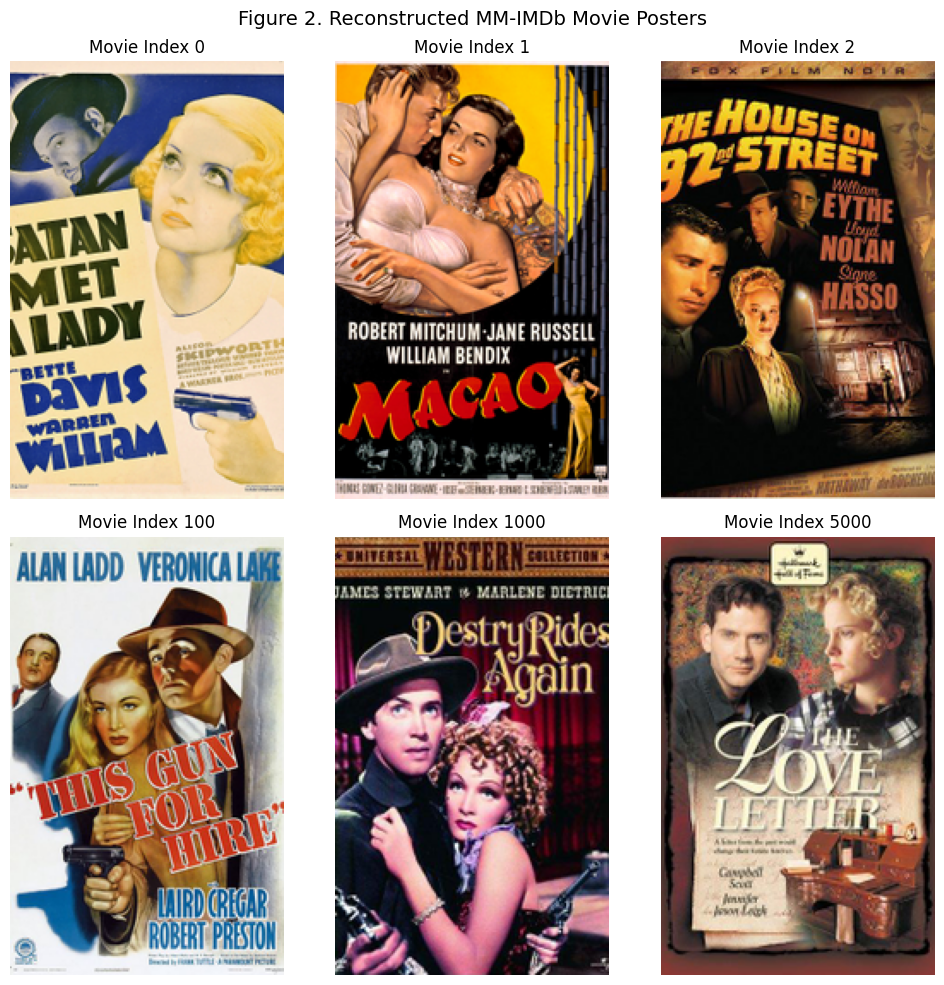

In [30]:
# Display reconstructed poster samples

with h5py.File(HDF5_PATH, "r") as h5_file:

    images = h5_file[
        "images"
    ]

    sample_indices = [
        0,
        1,
        2,
        100,
        1000,
        5000
    ]

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(10, 10)
    )

    axes = axes.flatten()

    for ax, index in zip(
        axes,
        sample_indices
    ):

        poster = reconstruct_poster(
            images[index]
        )

        ax.imshow(
            poster
        )

        ax.set_title(
            f"Movie Index {index}"
        )

        ax.axis(
            "off"
        )

    fig.suptitle(
        "Figure 2. Reconstructed MM-IMDb Movie Posters",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

### Poster Reconstruction and Visual Verification

The stored poster tensors were reconstructed by reversing the VGG/Caffe-style preprocessing applied to the image data. This included restoring the channel-wise mean values, converting the stored BGR channel order to RGB, and constraining pixel values to the valid display range.

Visual inspection of multiple samples produced normal movie posters with sensible colours and recognizable content. This confirms that the `images` dataset contains valid visual information and that the preprocessing can be reversed when required for inspection or alternative feature extraction.

In [31]:
# 3.6 IMDb ID uniqueness and duplicate check


with h5py.File(HDF5_PATH, "r") as h5_file:

    imdb_ids = np.asarray(
        h5_file["imdb_ids"][:]
    )

print(
    "Total IMDb IDs:",
    len(imdb_ids)
)

print(
    "Unique IMDb IDs:",
    len(
        np.unique(imdb_ids)
    )
)

print(
    "Duplicate IMDb IDs:",
    len(imdb_ids)
    - len(
        np.unique(imdb_ids)
    )
)

print(
    "\nFirst 10 IMDb IDs:"
)

print(
    imdb_ids[:10]
)

Total IMDb IDs: 25959
Unique IMDb IDs: 25959
Duplicate IMDb IDs: 0

First 10 IMDb IDs:
[b'0028219' b'0044863' b'0037795' b'0042046' b'0047542' b'0044314'
 b'0046791' b'0037884' b'0049949' b'0049006']


# 4. Train, Validation and Test Split

A common train, validation and test split is created before feature extraction and model development. The same movie indices are retained across all modalities and modelling approaches so that unimodal and multimodal models are evaluated on identical observations.

Because MM-IMDb is a multi-label dataset with substantial genre imbalance, ordinary random stratification based on a single class label is not appropriate. Instead, iterative multi-label stratification is used to approximately preserve the prevalence of all 23 genre labels across the three subsets.

The dataset is divided into:

*   70% training data for model fitting,
*   15% validation data for hyperparameter selection, threshold optimisation and model selection,
*   15% test data reserved for final unbiased evaluation.

A fixed random seed is used to support reproducibility.

In [32]:
# 4.1 Installing multi-label stratification utility


!pip -q install iterative-stratification

In [33]:
from iterstrat.ml_stratifiers import (
    MultilabelStratifiedShuffleSplit
)

In [34]:
# 4.2 Creating common multi-label-stratified splits


all_indices = np.arange(
    genres.shape[0]
)

# First split:
# 70% training
# 30% temporary validation + test


split_train_temp = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=SEED
)

train_indices, temp_indices = next(
    split_train_temp.split(
        all_indices,
        genres
    )
)


# Second split:
# divide the remaining 30% equally into
# 15% validation and 15% test


temp_genres = genres[
    temp_indices
]

split_val_test = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED
)

val_relative, test_relative = next(
    split_val_test.split(
        temp_indices,
        temp_genres
    )
)

val_indices = temp_indices[
    val_relative
]

test_indices = temp_indices[
    test_relative
]

print(
    "Training samples:",
    len(train_indices)
)

print(
    "Validation samples:",
    len(val_indices)
)

print(
    "Test samples:",
    len(test_indices)
)

print(
    "\nTotal samples:",
    len(train_indices)
    + len(val_indices)
    + len(test_indices)
)

Training samples: 18148
Validation samples: 3908
Test samples: 3903

Total samples: 25959


In [35]:
# 4.3 Checking for split overlap


train_set = set(
    train_indices
)

val_set = set(
    val_indices
)

test_set = set(
    test_indices
)

print(
    "Train / validation overlap:",
    len(
        train_set & val_set
    )
)

print(
    "Train / test overlap:",
    len(
        train_set & test_set
    )
)

print(
    "Validation / test overlap:",
    len(
        val_set & test_set
    )
)

Train / validation overlap: 0
Train / test overlap: 0
Validation / test overlap: 0


In [36]:
# 4.4 Compare genre prevalence across splits


y_train = genres[
    train_indices
]

y_val = genres[
    val_indices
]

y_test = genres[
    test_indices
]

genre_split_df = pd.DataFrame({
    "Genre": genre_names,

    "Full Dataset": (
        genres.mean(
            axis=0
        )
    ),

    "Training": (
        y_train.mean(
            axis=0
        )
    ),

    "Validation": (
        y_val.mean(
            axis=0
        )
    ),

    "Test": (
        y_test.mean(
            axis=0
        )
    )
})

display(
    genre_split_df.round(4)
)

,Genre,Full Dataset,Training,Validation,Test
0,Drama,0.5380,0.5387,0.5361,0.5368
1,Comedy,0.3310,0.3314,0.3298,0.3303
2,Romance,0.2066,0.2069,0.2057,0.2063
3,Thriller,0.2000,0.2002,0.1993,0.1996
4,Crime,0.1478,0.1481,0.1471,0.1476
5,Action,0.1368,0.1369,0.1361,0.1366
6,Adventure,0.1044,0.1045,0.1039,0.1043
7,Horror,0.1041,0.1043,0.1036,0.1040
8,Documentary,0.0802,0.0803,0.0798,0.0802
9,Mystery,0.0792,0.0793,0.0788,0.0792


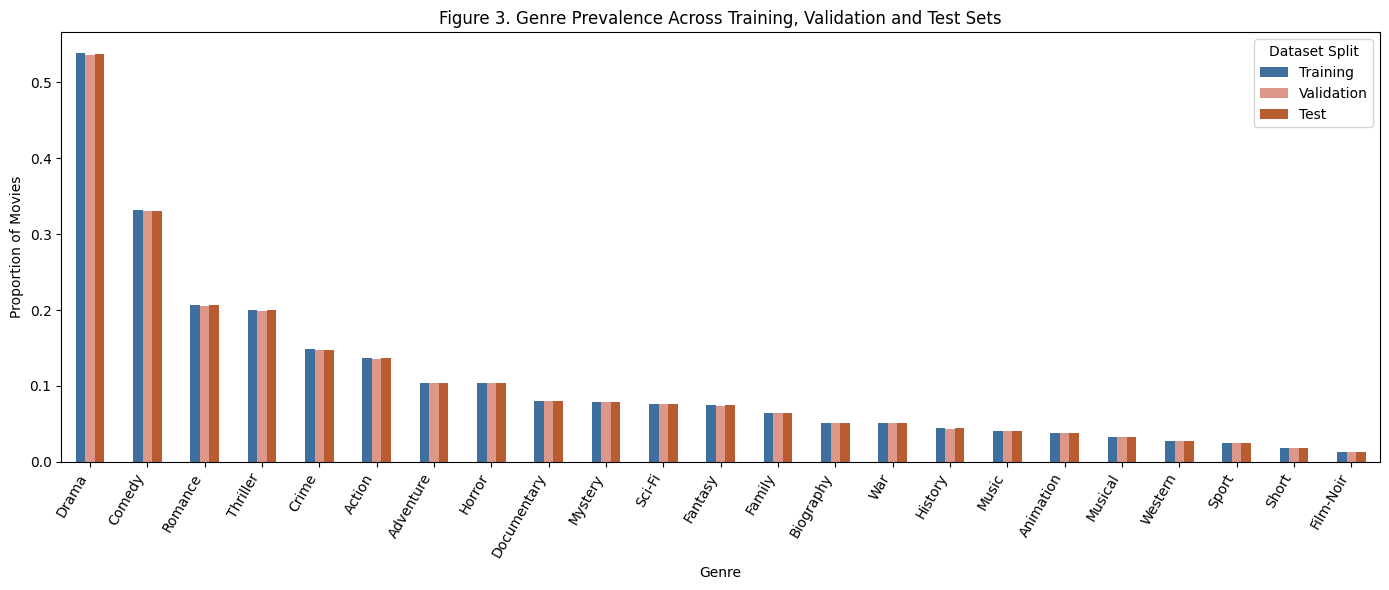

In [38]:
# 4.5 Visualise genre prevalence across data splits

split_plot_df = (
    genre_split_df
    .set_index("Genre")[
        [
            "Training",
            "Validation",
            "Test"
        ]
    ]
)

ax = split_plot_df.plot(
    kind="bar",
    figsize=(14, 6),
    color=[
        "#3f6f9f",
        "#dc9789",
        "#b95c32"
    ]
)

ax.set_title(
    "Figure 3. Genre Prevalence Across "
    "Training, Validation and Test Sets"
)

ax.set_xlabel(
    "Genre"
)

ax.set_ylabel(
    "Proportion of Movies"
)

plt.xticks(
    rotation=60,
    ha="right"
)

plt.legend(
    title="Dataset Split"
)

plt.tight_layout()
plt.show()

In [39]:
# 4.6 Quantify maximum prevalence differences


full_prevalence = genres.mean(
    axis=0
)

train_difference = np.abs(
    y_train.mean(axis=0)
    - full_prevalence
)

val_difference = np.abs(
    y_val.mean(axis=0)
    - full_prevalence
)

test_difference = np.abs(
    y_test.mean(axis=0)
    - full_prevalence
)

print(
    "Maximum training prevalence difference:",
    round(
        train_difference.max(),
        4
    )
)

print(
    "Maximum validation prevalence difference:",
    round(
        val_difference.max(),
        4
    )
)

print(
    "Maximum test prevalence difference:",
    round(
        test_difference.max(),
        4
    )
)

Maximum training prevalence difference: 0.0007
Maximum validation prevalence difference: 0.002
Maximum test prevalence difference: 0.0013


### Split Verification

Iterative multi-label stratification was used to divide the 25,959 MM-IMDb samples into common training, validation and test subsets while preserving the prevalence of all 23 genre labels.

The resulting subsets contained:

*   18,148 training samples,
*   3,908 validation samples,
*   3,903 test samples.

No movie index appeared in more than one subset, with zero overlap between the training, validation and test sets. This ensures that the final evaluation is performed on observations that were not used during model fitting or model selection.

The genre-prevalence distributions were also compared across the three subsets. The maximum absolute difference from the full-dataset prevalence was only 0.0007 for the training set, 0.0002 for the validation set and 0.0013 for the test set. Figure 3 further demonstrates that the genre distributions are closely aligned across all partitions, including the less frequent classes.

The same indices will be retained for both poster and plot modalities and reused across all unimodal and multimodal experiments. This provides a consistent basis for comparing the different feature extraction and fusion strategies.

# 5. Feature Extraction

Feature extraction converts the two MM-IMDb modalities into numerical representations suitable for classification and multimodal fusion.

Two representation levels are considered. First, the precomputed visual and textual features supplied with MM-IMDb are retained as computationally efficient baseline representations. Second, modern pretrained encoders are used to obtain stronger semantic representations from the reconstructed movie posters and decoded plot summaries.

This allows the project to compare traditional feature-level fusion against representations produced by recent pretrained models while maintaining the same train, validation and test partitions.

In [40]:
# 5.1 Loading precomputed visual and textual features


with h5py.File(HDF5_PATH, "r") as h5_file:

    vgg_features = np.asarray(
        h5_file["vgg_features"][:]
    )

    text_features = np.asarray(
        h5_file["features"][:]
    )

print(
    "VGG visual feature shape:",
    vgg_features.shape
)

print(
    "Text feature shape:",
    text_features.shape
)

VGG visual feature shape: (25959, 4096)
Text feature shape: (25959, 300)


In [41]:
# 5.2 Basic feature-quality checks


def feature_quality_summary(
    name,
    features
):

    print(
        f"\n{name}"
    )

    print(
        "Shape:",
        features.shape
    )

    print(
        "Missing values:",
        np.isnan(
            features
        ).sum()
    )

    print(
        "Infinite values:",
        np.isinf(
            features
        ).sum()
    )

    feature_variance = np.var(
        features,
        axis=0
    )

    print(
        "Zero-variance features:",
        np.sum(
            feature_variance == 0
        )
    )

    print(
        "Mean feature variance:",
        round(
            feature_variance.mean(),
            6
        )
    )


feature_quality_summary(
    "VGG visual features",
    vgg_features
)

feature_quality_summary(
    "Text features",
    text_features
)


VGG visual features
Shape: (25959, 4096)
Missing values: 0
Infinite values: 0
Zero-variance features: 13
Mean feature variance: 0.95909

Text features
Shape: (25959, 300)
Missing values: 0
Infinite values: 0
Zero-variance features: 0
Mean feature variance: 0.000683


In [42]:
# 5.3 Apply common data split to extracted features

X_visual_train = vgg_features[
    train_indices
]

X_visual_val = vgg_features[
    val_indices
]

X_visual_test = vgg_features[
    test_indices
]


X_text_train = text_features[
    train_indices
]

X_text_val = text_features[
    val_indices
]

X_text_test = text_features[
    test_indices
]


print(
    "Visual training features:",
    X_visual_train.shape
)

print(
    "Visual validation features:",
    X_visual_val.shape
)

print(
    "Visual test features:",
    X_visual_test.shape
)

print()

print(
    "Text training features:",
    X_text_train.shape
)

print(
    "Text validation features:",
    X_text_val.shape
)

print(
    "Text test features:",
    X_text_test.shape
)

Visual training features: (18148, 4096)
Visual validation features: (3908, 4096)
Visual test features: (3903, 4096)

Text training features: (18148, 300)
Text validation features: (3908, 300)
Text test features: (3903, 300)


### Precomputed Feature Quality

The MM-IMDb dataset provides a 4,096-dimensional VGG representation for the poster modality and a 300-dimensional representation for the textual modality. Both feature matrices contain all 25,959 movies and remain aligned with the common training, validation and test partitions.

No missing or infinite values were identified in either modality. The textual representation contained no zero-variance dimensions, whereas 13 of the 4,096 VGG dimensions had zero variance and therefore contain no discriminative information. These constant visual features are removed before modelling.

The visual and textual feature spaces also exhibit substantially different numerical scales, with mean feature variances of 0.95909 and 0.000683 respectively. Consequently, scaling is performed independently for each modality using parameters estimated only from the training partition. This avoids information leakage and prevents the higher-magnitude visual representation from dominating feature-level fusion solely because of scale.

In [43]:
# 5.4 Remove zero-variance visual features


visual_variance = np.var(
    X_visual_train,
    axis=0
)

visual_feature_mask = (
    visual_variance > 0
)

print(
    "Original visual dimensions:",
    X_visual_train.shape[1]
)

print(
    "Zero-variance dimensions removed:",
    np.sum(
        ~visual_feature_mask
    )
)

X_visual_train_clean = X_visual_train[
    :,
    visual_feature_mask
]

X_visual_val_clean = X_visual_val[
    :,
    visual_feature_mask
]

X_visual_test_clean = X_visual_test[
    :,
    visual_feature_mask
]

print(
    "Clean visual training shape:",
    X_visual_train_clean.shape
)

print(
    "Clean visual validation shape:",
    X_visual_val_clean.shape
)

print(
    "Clean visual test shape:",
    X_visual_test_clean.shape
)

Original visual dimensions: 4096
Zero-variance dimensions removed: 13
Clean visual training shape: (18148, 4083)
Clean visual validation shape: (3908, 4083)
Clean visual test shape: (3903, 4083)


In [44]:
# 5.5 Standardise precomputed features


from sklearn.preprocessing import StandardScaler

visual_scaler = StandardScaler()
text_scaler = StandardScaler()

# Fit only on training data
X_visual_train_scaled = (
    visual_scaler.fit_transform(
        X_visual_train_clean
    )
)

X_visual_val_scaled = (
    visual_scaler.transform(
        X_visual_val_clean
    )
)

X_visual_test_scaled = (
    visual_scaler.transform(
        X_visual_test_clean
    )
)


X_text_train_scaled = (
    text_scaler.fit_transform(
        X_text_train
    )
)

X_text_val_scaled = (
    text_scaler.transform(
        X_text_val
    )
)

X_text_test_scaled = (
    text_scaler.transform(
        X_text_test
    )
)

print(
    "Scaled visual training shape:",
    X_visual_train_scaled.shape
)

print(
    "Scaled text training shape:",
    X_text_train_scaled.shape
)

print(
    "\nVisual training mean:",
    round(
        X_visual_train_scaled.mean(),
        6
    )
)

print(
    "Visual training std:",
    round(
        X_visual_train_scaled.std(),
        6
    )
)

print(
    "Text training mean:",
    round(
        X_text_train_scaled.mean(),
        6
    )
)

print(
    "Text training std:",
    round(
        X_text_train_scaled.std(),
        6
    )
)

Scaled visual training shape: (18148, 4083)
Scaled text training shape: (18148, 300)

Visual training mean: 0.0
Visual training std: 1.0
Text training mean: 0.0
Text training std: 1.0


### Modern Multimodal Representation

In addition to the supplied MM-IMDb representations, CLIP is used as a modern pretrained multimodal feature extractor. CLIP employs separate visual and textual encoders trained contrastively so that semantically related images and text occupy a shared embedding space.

This is particularly suitable for MM-IMDb because movie posters and plot summaries provide complementary visual and semantic information. The pretrained encoder is used for feature extraction rather than full fine-tuning, reducing GPU and training requirements while retaining representations learnt from large-scale image-text data.

In [45]:
# 5.6 Preparing CLIP feature extractor


!pip -q install transformers

In [46]:
import torch

from transformers import (
    CLIPModel,
    CLIPProcessor
)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Device:",
    device
)

CLIP_MODEL_NAME = (
    "openai/clip-vit-base-patch32"
)

clip_model = CLIPModel.from_pretrained(
    CLIP_MODEL_NAME
).to(
    device
)

clip_processor = CLIPProcessor.from_pretrained(
    CLIP_MODEL_NAME
)

clip_model.eval()

print(
    "CLIP model loaded successfully."
)

Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (4 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model loaded successfully.


In [48]:
# 5.7 Test CLIP extraction on a small batch

test_indices_clip = [
    0,
    1,
    2,
    3
]

test_posters = []
test_plots = []

with h5py.File(HDF5_PATH, "r") as h5_file:
    images = h5_file["images"]
    sequences = h5_file["sequences"]

    for index in test_indices_clip:
        # Reconstruct poster
        poster = reconstruct_poster(
            images[index]
        )
        test_posters.append(
            poster
        )

        # Decode plot
        plot = decode_sequence(
            np.asarray(
                sequences[index]
            ),
            ix_to_word
        )
        test_plots.append(
            plot
        )

with torch.no_grad():
    # Process both modalities together
    inputs = clip_processor(
        text=test_plots,
        images=test_posters,
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    # Run CLIP model forward pass
    outputs = clip_model(**inputs)

    # Extract projection embeddings (comparable representations)
    clip_image_features = outputs.image_embeds
    clip_text_features = outputs.text_embeds

print(
    "CLIP image feature shape:",
    clip_image_features.shape
)

print(
    "CLIP text feature shape:",
    clip_text_features.shape
)

CLIP image feature shape: torch.Size([4, 512])
CLIP text feature shape: torch.Size([4, 512])


### Feature Extraction Verification

The supplied MM-IMDb visual and textual representations were successfully prepared for modelling. Thirteen zero-variance dimensions were removed from the 4,096 dimensional VGG feature space, resulting in 4,083 informative visual dimensions. The 300 dimensional textual representation required no feature removal.

Both modalities were standardised independently using parameters estimated only from the training partition. The resulting training representations have approximately zero mean and unit standard deviation. This prevents differences in numerical scale from dominating subsequent feature-level fusion.

A modern CLIP-based feature extraction pipeline was also validated using a small batch of reconstructed movie posters and decoded plot summaries. The pretrained CLIP model produced 512 dimensional embeddings for both the visual and textual modalities. This confirms compatibility with the MM-IMDb data and enabling a modern shared-embedding comparison with the supplied baseline representations.

# 6. Modelling and Multimodal Fusion


This section develops and compares unimodal and multimodal genre classification models using the common training, validation and test partitions established previously.

Because each movie may belong to multiple genres simultaneously, the task is formulated as multi-label classification. Each of the 23 genre outputs is therefore treated as an independent binary prediction while the complete set of labels is predicted jointly for each movie.

The modelling experiments are organised as follows:

*   visual-only and text-only unimodal baselines,
*   early fusion of the visual and textual feature representations,
*   late fusion of independently trained modality-specific classifiers,
*   modern fusion using CLIP-derived multimodal embeddings,
*   validation-based decision-threshold optimisation,
*   comparative evaluation on the held-out test set.

The unimodal models provide reference points for determining whether multimodal fusion produces a genuine improvement over either modality.

### 6.1 Unimodal Baseline Models

Two unimodal baseline classifiers are trained independently using the visual and textual feature representations. A one-vs-rest logistic-regression strategy is used, where one binary classifier is fitted for each of the 23 genre labels.

Class weighting is enabled to reduce the influence of the substantial label imbalance observed during exploratory analysis. These unimodal models establish the performance achievable using each modality independently and provide the component classifiers required for subsequent late fusion.

In [49]:
# 6.1 Prepare unimodal baseline classifiers

from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    hamming_loss
)

In [50]:
# Visual-only baseline

visual_baseline = OneVsRestClassifier(
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        solver="liblinear",
        random_state=SEED
    ),
    n_jobs=-1
)


# Text-only baseline

text_baseline = OneVsRestClassifier(
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        solver="liblinear",
        random_state=SEED
    ),
    n_jobs=-1
)

In [52]:
# Training unimodal baseline models


from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import SGDClassifier

# SGD with log-loss behaves as a linear logistic classifier, but is substantially faster for large, high-dimensional data.

visual_baseline = OneVsRestClassifier(
    SGDClassifier(
        loss="log_loss",
        class_weight="balanced",
        max_iter=1000,
        tol=1e-3,
        random_state=SEED
    ),
    n_jobs=-1
)

text_baseline = OneVsRestClassifier(
    SGDClassifier(
        loss="log_loss",
        class_weight="balanced",
        max_iter=1000,
        tol=1e-3,
        random_state=SEED
    ),
    n_jobs=-1
)


print(
    "Training visual-only baseline..."
)

visual_baseline.fit(
    X_visual_train_scaled,
    y_train
)

print(
    "Visual-only baseline trained."
)


print(
    "\nTraining text-only baseline..."
)

text_baseline.fit(
    X_text_train_scaled,
    y_train
)

print(
    "Text-only baseline trained."
)

Training visual-only baseline...
Visual-only baseline trained.

Training text-only baseline...
Text-only baseline trained.


In [53]:
# 6.2 Generate unimodal validation probabilities


visual_val_prob = visual_baseline.predict_proba(
    X_visual_val_scaled
)

text_val_prob = text_baseline.predict_proba(
    X_text_val_scaled
)

print(
    "Visual probability shape:",
    visual_val_prob.shape
)

print(
    "Text probability shape:",
    text_val_prob.shape
)

Visual probability shape: (3908, 23)
Text probability shape: (3908, 23)


In [54]:
# Initial multi-label predictions using a 0.50 threshold

INITIAL_THRESHOLD = 0.50

visual_val_pred = (
    visual_val_prob
    >= INITIAL_THRESHOLD
).astype(int)

text_val_pred = (
    text_val_prob
    >= INITIAL_THRESHOLD
).astype(int)

In [55]:
# Reusable multi-label evaluation function

def evaluate_multilabel_model(
    y_true,
    y_pred,
    model_name
):

    results = {
        "Model": model_name,

        "Micro F1": f1_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "Micro Precision": precision_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0
        ),

        "Micro Recall": recall_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0
        ),

        "Hamming Loss": hamming_loss(
            y_true,
            y_pred
        )
    }

    return results

In [56]:
# Evaluate unimodal models on validation data


visual_validation_results = (
    evaluate_multilabel_model(
        y_val,
        visual_val_pred,
        "Visual Only"
    )
)

text_validation_results = (
    evaluate_multilabel_model(
        y_val,
        text_val_pred,
        "Text Only"
    )
)

unimodal_validation_df = pd.DataFrame(
    [
        visual_validation_results,
        text_validation_results
    ]
)

display(
    unimodal_validation_df.round(4)
)

,Model,Micro F1,Macro F1,Weighted F1,Micro Precision,Micro Recall,Hamming Loss
0,Visual Only,0.3572,0.2663,0.3763,0.2985,0.4446,0.1721
1,Text Only,0.4226,0.3639,0.4959,0.2971,0.7318,0.2151


### Unimodal Baseline Performance

The text only baseline outperformed the visual only baseline at the initial 0.50 decision threshold. It achieved a Micro F1-score of 0.4226 and a Macro F1-score of 0.3639, compared with 0.3572 and 0.2663 respectively for the visual model.

The text model also achieved higher Micro Recall (0.7318). This suggests that plot summaries contain strong semantic information for genre identification. So, its relatively low precision and higher Hamming loss indicate a tendency to predict additional genre labels. These results provide the unimodal reference points against which the multimodal fusion strategies are evaluated.

### 6.4 Early Fusion

Early fusion combines the visual and textual representations before classification. Because each modality was independently standardised using training-set statistics, the feature spaces can be concatenated without allowing one modality to dominate because of numerical scale.

The resulting 4,383 dimensional multimodal representation is supplied to a one-vs-rest linear classifier. This approach allows each genre classifier to jointly learn relationships between visual poster characteristics and textual plot information.

In [57]:
# 6.4 constructing early-fusion feature representations

X_early_train = np.concatenate(
    [
        X_visual_train_scaled,
        X_text_train_scaled
    ],
    axis=1
)

X_early_val = np.concatenate(
    [
        X_visual_val_scaled,
        X_text_val_scaled
    ],
    axis=1
)

X_early_test = np.concatenate(
    [
        X_visual_test_scaled,
        X_text_test_scaled
    ],
    axis=1
)

print(
    "Early-fusion training shape:",
    X_early_train.shape
)

print(
    "Early-fusion validation shape:",
    X_early_val.shape
)

print(
    "Early-fusion test shape:",
    X_early_test.shape
)

Early-fusion training shape: (18148, 4383)
Early-fusion validation shape: (3908, 4383)
Early-fusion test shape: (3903, 4383)


In [58]:
# Train early-fusion classifier


early_fusion_model = OneVsRestClassifier(
    SGDClassifier(
        loss="log_loss",
        class_weight="balanced",
        max_iter=1000,
        tol=1e-3,
        random_state=SEED
    ),
    n_jobs=-1
)

print(
    "Training early-fusion model..."
)

early_fusion_model.fit(
    X_early_train,
    y_train
)

print(
    "Early-fusion model trained."
)

Training early-fusion model...
Early-fusion model trained.


In [59]:
# Evaluating early fusion on validation set


early_val_prob = early_fusion_model.predict_proba(
    X_early_val
)

early_val_pred = (
    early_val_prob >= 0.50
).astype(int)

early_validation_results = (
    evaluate_multilabel_model(
        y_val,
        early_val_pred,
        "Early Fusion"
    )
)

display(
    pd.DataFrame(
        [early_validation_results]
    ).round(4)
)

,Model,Micro F1,Macro F1,Weighted F1,Micro Precision,Micro Recall,Hamming Loss
0,Early Fusion,0.4981,0.4303,0.502,0.4761,0.5223,0.1132


### 6.5 Late Fusion

Late fusion preserves separate modality-specific classifiers and combines their prediction probabilities after independent inference. This allows each modality to retain its specialised representation and makes the system less dependent on a single joint feature space.

The relative contribution of the visual and textual classifiers is selected using the validation set rather than assigned arbitrarily. Candidate visual weights are evaluated from 0 to 1, while the corresponding text weight is defined as (1-w). The combination producing the highest validation Macro F1-score is retained.

In [60]:
# 6.5 Optimise late-fusion modality weights


weight_results = []

for visual_weight in np.arange(
    0.0,
    1.01,
    0.05
):

    text_weight = (
        1.0 - visual_weight
    )

    fused_prob = (
        visual_weight * visual_val_prob
        +
        text_weight * text_val_prob
    )

    fused_pred = (
        fused_prob >= 0.50
    ).astype(int)

    macro_f1 = f1_score(
        y_val,
        fused_pred,
        average="macro",
        zero_division=0
    )

    micro_f1 = f1_score(
        y_val,
        fused_pred,
        average="micro",
        zero_division=0
    )

    weight_results.append({
        "Visual Weight": visual_weight,
        "Text Weight": text_weight,
        "Macro F1": macro_f1,
        "Micro F1": micro_f1
    })


weight_results_df = pd.DataFrame(
    weight_results
)

display(
    weight_results_df.round(4)
)

,Visual Weight,Text Weight,Macro F1,Micro F1
0,0.00,1.00,0.3639,0.4226
1,0.05,0.95,0.3658,0.4250
2,0.10,0.90,0.3681,0.4281
3,0.15,0.85,0.3698,0.4305
4,0.20,0.80,0.3728,0.4339
5,0.25,0.75,0.3751,0.4361
6,0.30,0.70,0.3764,0.4378
7,0.35,0.65,0.3775,0.4378
8,0.40,0.60,0.3798,0.4377
9,0.45,0.55,0.3788,0.4326


In [61]:
# select the modality weighting with highest Macro F1

best_weight_row = (
    weight_results_df
    .loc[
        weight_results_df[
            "Macro F1"
        ].idxmax()
    ]
)

BEST_VISUAL_WEIGHT = float(
    best_weight_row[
        "Visual Weight"
    ]
)

BEST_TEXT_WEIGHT = float(
    best_weight_row[
        "Text Weight"
    ]
)

print(
    "Best visual weight:",
    round(
        BEST_VISUAL_WEIGHT,
        2
    )
)

print(
    "Best text weight:",
    round(
        BEST_TEXT_WEIGHT,
        2
    )
)

print(
    "Best validation Macro F1:",
    round(
        best_weight_row[
            "Macro F1"
        ],
        4
    )
)

Best visual weight: 0.4
Best text weight: 0.6
Best validation Macro F1: 0.3798


In [62]:
# evaluating optimised late fusion


late_val_prob = (
    BEST_VISUAL_WEIGHT
    * visual_val_prob
    +
    BEST_TEXT_WEIGHT
    * text_val_prob
)

late_val_pred = (
    late_val_prob >= 0.50
).astype(int)

late_validation_results = (
    evaluate_multilabel_model(
        y_val,
        late_val_pred,
        "Late Fusion"
    )
)

display(
    pd.DataFrame(
        [late_validation_results]
    ).round(4)
)

,Model,Micro F1,Macro F1,Weighted F1,Micro Precision,Micro Recall,Hamming Loss
0,Late Fusion,0.4377,0.3798,0.4997,0.3199,0.693,0.1915


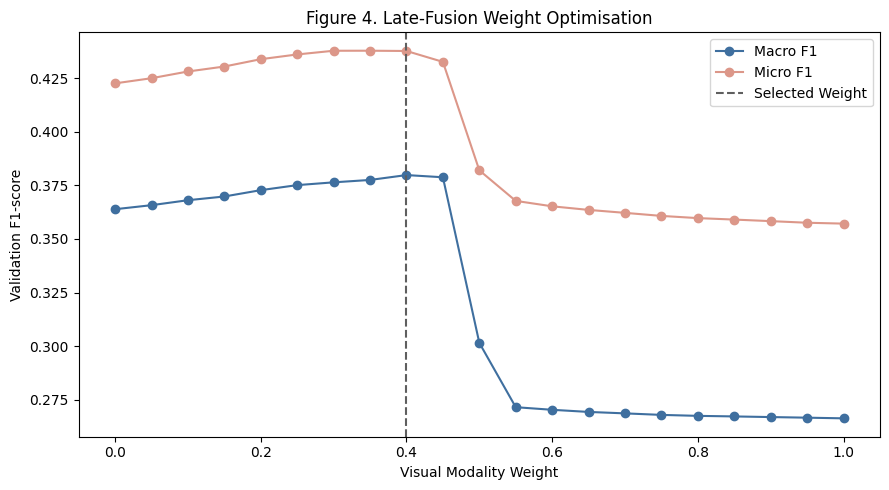

In [63]:
# visualising late-fusion weight optimisation

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    weight_results_df[
        "Visual Weight"
    ],
    weight_results_df[
        "Macro F1"
    ],
    marker="o",
    color="#3f6f9f",
    label="Macro F1"
)

plt.plot(
    weight_results_df[
        "Visual Weight"
    ],
    weight_results_df[
        "Micro F1"
    ],
    marker="o",
    color="#dc9789",
    label="Micro F1"
)

plt.axvline(
    BEST_VISUAL_WEIGHT,
    linestyle="--",
    color="#5f5f5f",
    label="Selected Weight"
)

plt.title(
    "Figure 4. Late-Fusion Weight Optimisation"
)

plt.xlabel(
    "Visual Modality Weight"
)

plt.ylabel(
    "Validation F1-score"
)

plt.legend()

plt.tight_layout()
plt.show()

### 6.6 CLIP-Based Modern Multimodal Fusion

A modern multimodal representation is constructed using the pretrained CLIP image and text encoders. Unlike the supplied VGG and 300 dimensional text representations, CLIP has been contrastively trained to position semantically related visual and textual content within a shared embedding space.

Each movie is represented by a 512 dimensional poster embedding and a 512 dimensional plot-summary embedding. The embeddings are L2-normalised and concatenated to produce a 1,024-dimensional multimodal representation. A one-vs-rest linear classifier is then trained using the same training, validation and test partitions as the previous approaches.

The pretrained CLIP encoders are kept frozen to reduce computational requirements and make the experiment feasible within the available Colab GPU budget.

In [75]:
# 6.6 Extract and cache CLIP embeddings

# extracting and caching CLIP embeddings

from pathlib import Path
import torch
import numpy as np
import h5py

CLIP_CACHE_DIR = PROJECT_DIR / "clip_features"

CLIP_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CLIP_IMAGE_PATH = (
    CLIP_CACHE_DIR / "clip_image_features.npy"
)

CLIP_TEXT_PATH = (
    CLIP_CACHE_DIR / "clip_text_features.npy"
)

BATCH_SIZE = 64


def extract_clip_features():

    image_feature_batches = []
    text_feature_batches = []

    with h5py.File(
        HDF5_PATH,
        "r"
    ) as h5_file:

        images = h5_file[
            "images"
        ]

        sequences = h5_file[
            "sequences"
        ]

        total_samples = len(
            images
        )

        for start in range(
            0,
            total_samples,
            BATCH_SIZE
        ):

            end = min(
                start + BATCH_SIZE,
                total_samples
            )

            batch_posters = []
            batch_plots = []

            for index in range(
                start,
                end
            ):

                poster = reconstruct_poster(
                    images[index]
                )

                plot = decode_sequence(
                    np.asarray(
                        sequences[index]
                    ),
                    ix_to_word
                )

                batch_posters.append(
                    poster
                )

                batch_plots.append(
                    plot
                )

            image_inputs = clip_processor(
                images=batch_posters,
                return_tensors="pt"
            )

            image_inputs = {
                key: value.to(
                    device
                )
                for key, value
                in image_inputs.items()
            }

            text_inputs = clip_processor(
                text=batch_plots,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=77
            )

            text_inputs = {
                key: value.to(
                    device
                )
                for key, value
                in text_inputs.items()
            }

            with torch.no_grad():

                image_output = (
                    clip_model.get_image_features(
                        **image_inputs
                    )
                )

                text_output = (
                    clip_model.get_text_features(
                        **text_inputs
                    )
                )

                # Handle different Transformers return types
                if hasattr(
                    image_output,
                    "pooler_output"
                ):

                    image_features = (
                        image_output.pooler_output
                    )

                else:

                    image_features = (
                        image_output
                    )


                if hasattr(
                    text_output,
                    "pooler_output"
                ):

                    text_features_batch = (
                        text_output.pooler_output
                    )

                else:

                    text_features_batch = (
                        text_output
                    )

                # L2-normalise the embeddings
                image_features = (
                    image_features
                    /
                    image_features.norm(
                        dim=1,
                        keepdim=True
                    )
                )

                text_features_batch = (
                    text_features_batch
                    /
                    text_features_batch.norm(
                        dim=1,
                        keepdim=True
                    )
                )

            image_feature_batches.append(
                image_features
                .cpu()
                .numpy()
            )

            text_feature_batches.append(
                text_features_batch
                .cpu()
                .numpy()
            )

            if (
                start == 0
                or
                end % 1000 < BATCH_SIZE
                or
                end == total_samples
            ):

                print(
                    f"Processed {end:,} / "
                    f"{total_samples:,} movies"
                )

    clip_image_features_all = (
        np.vstack(
            image_feature_batches
        )
    )

    clip_text_features_all = (
        np.vstack(
            text_feature_batches
        )
    )

    np.save(
        str(
            CLIP_IMAGE_PATH
        ),
        clip_image_features_all
    )

    np.save(
        str(
            CLIP_TEXT_PATH
        ),
        clip_text_features_all
    )

    return (
        clip_image_features_all,
        clip_text_features_all
    )


# Load cached features if available;
# otherwise extract and save them

if (
    CLIP_IMAGE_PATH.exists()
    and
    CLIP_TEXT_PATH.exists()
):

    print(
        "Loading cached CLIP features..."
    )

    clip_image_features_all = np.load(
        str(
            CLIP_IMAGE_PATH
        )
    )

    clip_text_features_all = np.load(
        str(
            CLIP_TEXT_PATH
        )
    )

else:

    print(
        "Cached CLIP features not found."
    )

    print(
        "Extracting CLIP features..."
    )

    (
        clip_image_features_all,
        clip_text_features_all
    ) = extract_clip_features()


print(
    "\nCLIP image feature matrix:",
    clip_image_features_all.shape
)

print(
    "CLIP text feature matrix:",
    clip_text_features_all.shape
)

Cached CLIP features not found.
Extracting CLIP features...
Processed 64 / 25,959 movies
Processed 1,024 / 25,959 movies
Processed 2,048 / 25,959 movies
Processed 3,008 / 25,959 movies
Processed 4,032 / 25,959 movies
Processed 5,056 / 25,959 movies
Processed 6,016 / 25,959 movies
Processed 7,040 / 25,959 movies
Processed 8,000 / 25,959 movies
Processed 9,024 / 25,959 movies
Processed 10,048 / 25,959 movies
Processed 11,008 / 25,959 movies
Processed 12,032 / 25,959 movies
Processed 13,056 / 25,959 movies
Processed 14,016 / 25,959 movies
Processed 15,040 / 25,959 movies
Processed 16,000 / 25,959 movies
Processed 17,024 / 25,959 movies
Processed 18,048 / 25,959 movies
Processed 19,008 / 25,959 movies
Processed 20,032 / 25,959 movies
Processed 21,056 / 25,959 movies
Processed 22,016 / 25,959 movies
Processed 23,040 / 25,959 movies
Processed 24,000 / 25,959 movies
Processed 25,024 / 25,959 movies
Processed 25,959 / 25,959 movies

CLIP image feature matrix: (25959, 512)
CLIP text feature mat

In [78]:
# 6.7 Construct CLIP early-fusion representation


X_clip = np.concatenate(
    [
        clip_image_features_all,
        clip_text_features_all
    ],
    axis=1
)

X_clip_train = X_clip[
    train_indices
]

X_clip_val = X_clip[
    val_indices
]

X_clip_test = X_clip[
    test_indices
]

print(
    "CLIP fused training shape:",
    X_clip_train.shape
)

print(
    "CLIP fused validation shape:",
    X_clip_val.shape
)

print(
    "CLIP fused test shape:",
    X_clip_test.shape
)

CLIP fused training shape: (18148, 1024)
CLIP fused validation shape: (3908, 1024)
CLIP fused test shape: (3903, 1024)


In [79]:
# Train CLIP-based multimodal classifier


clip_fusion_model = OneVsRestClassifier(
    SGDClassifier(
        loss="log_loss",
        class_weight="balanced",
        max_iter=1000,
        tol=1e-3,
        random_state=SEED
    ),
    n_jobs=-1
)

print(
    "Training CLIP-fusion classifier..."
)

clip_fusion_model.fit(
    X_clip_train,
    y_train
)

print(
    "CLIP-fusion classifier trained."
)

Training CLIP-fusion classifier...
CLIP-fusion classifier trained.


In [80]:
# Initial CLIP validation performance


clip_val_prob = (
    clip_fusion_model.predict_proba(
        X_clip_val
    )
)

clip_val_pred = (
    clip_val_prob >= 0.50
).astype(int)

clip_validation_results = (
    evaluate_multilabel_model(
        y_val,
        clip_val_pred,
        "CLIP Fusion"
    )
)

display(
    pd.DataFrame(
        [clip_validation_results]
    ).round(4)
)

,Model,Micro F1,Macro F1,Weighted F1,Micro Precision,Micro Recall,Hamming Loss
0,CLIP Fusion,0.5853,0.5261,0.6248,0.4719,0.7704,0.1174


### 6.8 Decision-Threshold Optimisation

The conventional probability threshold of 0.50 is not necessarily optimal for an imbalanced multi-label classification problem. A lower threshold increases label recall and a higher threshold favours precision.

A global decision threshold is selected using only the validation partition. Candidate thresholds between 0.20 and 0.80 are evaluated using Macro F1, which gives equal importance to each genre and is appropriate for the strongly imbalanced target distribution. The test set remains untouched during threshold selection.

In [81]:
# 6.8 Global threshold optimisation


def optimise_threshold(
    probabilities,
    y_true,
    model_name
):

    threshold_results = []

    thresholds = np.arange(
        0.20,
        0.81,
        0.02
    )

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        macro_f1 = f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        )

        micro_f1 = f1_score(
            y_true,
            predictions,
            average="micro",
            zero_division=0
        )

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Macro F1": macro_f1,
            "Micro F1": micro_f1
        })

    result_df = pd.DataFrame(
        threshold_results
    )

    best_row = result_df.loc[
        result_df[
            "Macro F1"
        ].idxmax()
    ]

    return (
        result_df,
        float(
            best_row[
                "Threshold"
            ]
        )
    )

In [82]:
# Early fusion

early_threshold_df, \
BEST_EARLY_THRESHOLD = optimise_threshold(
    early_val_prob,
    y_val,
    "Early Fusion"
)


# Late fusion

late_threshold_df, \
BEST_LATE_THRESHOLD = optimise_threshold(
    late_val_prob,
    y_val,
    "Late Fusion"
)


# CLIP fusion

clip_threshold_df, \
BEST_CLIP_THRESHOLD = optimise_threshold(
    clip_val_prob,
    y_val,
    "CLIP Fusion"
)


print(
    "Best Early Fusion threshold:",
    round(
        BEST_EARLY_THRESHOLD,
        2
    )
)

print(
    "Best Late Fusion threshold:",
    round(
        BEST_LATE_THRESHOLD,
        2
    )
)

print(
    "Best CLIP Fusion threshold:",
    round(
        BEST_CLIP_THRESHOLD,
        2
    )
)

Best Early Fusion threshold: 0.2
Best Late Fusion threshold: 0.56
Best CLIP Fusion threshold: 0.74


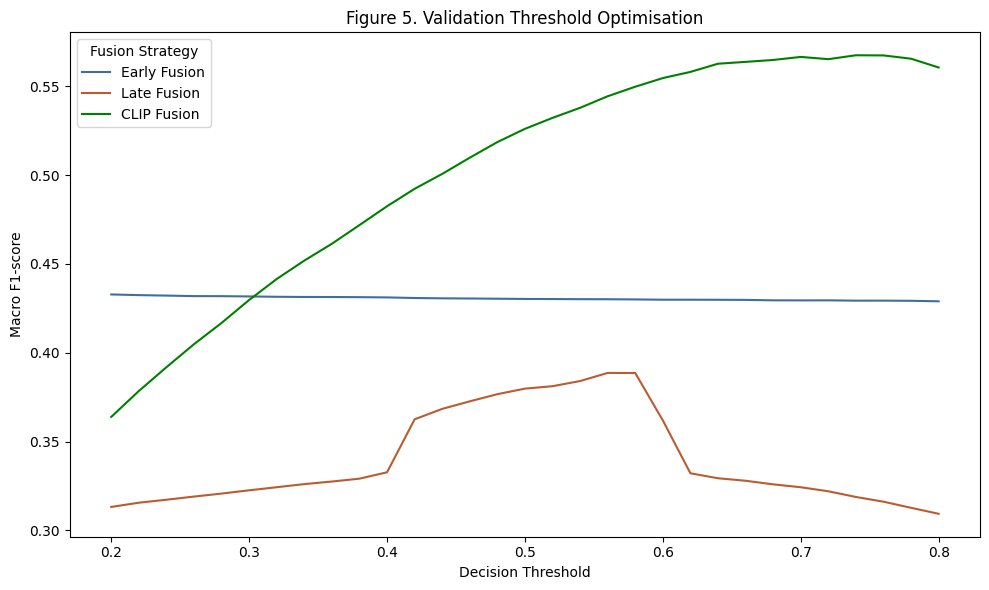

In [84]:
# visualising validation threshold optimisation


plt.figure(
    figsize=(10, 6)
)

plt.plot(
    early_threshold_df[
        "Threshold"
    ],
    early_threshold_df[
        "Macro F1"
    ],
    color="#3f6f9f",
    label="Early Fusion"
)

plt.plot(
    late_threshold_df[
        "Threshold"
    ],
    late_threshold_df[
        "Macro F1"
    ],
    color="#b95c32",
    label="Late Fusion"
)

plt.plot(
    clip_threshold_df[
        "Threshold"
    ],
    clip_threshold_df[
        "Macro F1"
    ],
    color="#008000",
    label="CLIP Fusion"
)

plt.title(
    "Figure 5. Validation Threshold Optimisation"
)

plt.xlabel(
    "Decision Threshold"
)

plt.ylabel(
    "Macro F1-score"
)

plt.legend(
    title="Fusion Strategy"
)

plt.tight_layout()
plt.show()

In [85]:
# refiing early fusion threshold below the previous search boundary

early_refined_results = []

for threshold in np.arange(
    0.05,
    0.31,
    0.01
):

    predictions = (
        early_val_prob >= threshold
    ).astype(int)

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    micro_f1 = f1_score(
        y_val,
        predictions,
        average="micro",
        zero_division=0
    )

    early_refined_results.append({
        "Threshold": threshold,
        "Macro F1": macro_f1,
        "Micro F1": micro_f1
    })


early_refined_df = pd.DataFrame(
    early_refined_results
)

best_early_row = early_refined_df.loc[
    early_refined_df[
        "Macro F1"
    ].idxmax()
]

BEST_EARLY_THRESHOLD = float(
    best_early_row[
        "Threshold"
    ]
)

print(
    "Refined Early Fusion threshold:",
    round(
        BEST_EARLY_THRESHOLD,
        2
    )
)

print(
    "Validation Macro F1:",
    round(
        best_early_row[
            "Macro F1"
        ],
        4
    )
)

Refined Early Fusion threshold: 0.05
Validation Macro F1: 0.434


### 6.9 Final Held-Out Test Evaluation

All model selection, late fusion weighting and decision threshold optimisation were performed exclusively using the validation partition. The resulting configurations are now applied once to the untouched test set to estimate final generalisation performance.

No test-set information is used to modify model parameters, fusion weights or decision thresholds. This separation prevents test-set leakage and allows a fair comparison between the unimodal baselines and multimodal fusion strategies.

In [86]:
# generate final test-set probabilities

visual_test_prob = visual_baseline.predict_proba(
    X_visual_test_scaled
)

text_test_prob = text_baseline.predict_proba(
    X_text_test_scaled
)

early_test_prob = early_fusion_model.predict_proba(
    X_early_test
)

late_test_prob = (
    BEST_VISUAL_WEIGHT * visual_test_prob
    +
    BEST_TEXT_WEIGHT * text_test_prob
)

clip_test_prob = clip_fusion_model.predict_proba(
    X_clip_test
)

In [87]:
# optimise unimodal thresholds using validation data

visual_threshold_df, BEST_VISUAL_THRESHOLD = (
    optimise_threshold(
        visual_val_prob,
        y_val,
        "Visual Only"
    )
)

text_threshold_df, BEST_TEXT_THRESHOLD = (
    optimise_threshold(
        text_val_prob,
        y_val,
        "Text Only"
    )
)

print(
    "Visual-only threshold:",
    round(
        BEST_VISUAL_THRESHOLD,
        2
    )
)

print(
    "Text-only threshold:",
    round(
        BEST_TEXT_THRESHOLD,
        2
    )
)

Visual-only threshold: 0.2
Text-only threshold: 0.64


In [88]:
# apply validation-selected thresholds to the test set

visual_test_pred = (
    visual_test_prob >= BEST_VISUAL_THRESHOLD
).astype(int)

text_test_pred = (
    text_test_prob >= BEST_TEXT_THRESHOLD
).astype(int)

early_test_pred = (
    early_test_prob >= BEST_EARLY_THRESHOLD
).astype(int)

late_test_pred = (
    late_test_prob >= BEST_LATE_THRESHOLD
).astype(int)

clip_test_pred = (
    clip_test_prob >= BEST_CLIP_THRESHOLD
).astype(int)

In [89]:
# comparing all models on the untouched test set

final_test_results = [
    evaluate_multilabel_model(
        y_test,
        visual_test_pred,
        "Visual Only"
    ),

    evaluate_multilabel_model(
        y_test,
        text_test_pred,
        "Text Only"
    ),

    evaluate_multilabel_model(
        y_test,
        early_test_pred,
        "Early Fusion"
    ),

    evaluate_multilabel_model(
        y_test,
        late_test_pred,
        "Late Fusion"
    ),

    evaluate_multilabel_model(
        y_test,
        clip_test_pred,
        "CLIP Fusion"
    )
]

final_test_results_df = pd.DataFrame(
    final_test_results
)

display(
    final_test_results_df.round(4)
)

,Model,Micro F1,Macro F1,Weighted F1,Micro Precision,Micro Recall,Hamming Loss
0,Visual Only,0.3636,0.2606,0.3806,0.2965,0.4699,0.1774
1,Text Only,0.4115,0.3708,0.4760,0.3057,0.6294,0.1941
2,Early Fusion,0.5166,0.4419,0.5177,0.4718,0.5709,0.1152
3,Late Fusion,0.4347,0.3891,0.4900,0.3388,0.6062,0.1701
4,CLIP Fusion,0.5719,0.5676,0.5733,0.6282,0.5248,0.0848


### Final Test-Set Performance

The final evaluation on the untouched test partition shows that multimodal fusion consistently improves performance over the unimodal baselines, although the magnitude of improvement depends strongly on the fusion strategy.

The visual-only model achieved a Micro F1-score of 0.3636 and Macro F1-score of 0.2606, while the text-only model performed better with scores of 0.4115 and 0.3708 respectively. This confirms that plot summaries contain stronger standalone genre information than movie posters.

Among the traditional multimodal approaches, early fusion performed substantially better than late fusion. Early fusion achieved a Micro F1-score of 0.5166 and Macro F1-score of 0.4419, demonstrating that jointly modelling the standardised visual and textual features provides additional predictive information beyond either modality alone.

The strongest overall performance was obtained using CLIP-based multimodal fusion. CLIP Fusion achieved a Micro F1-score of 0.5719, Macro F1-score of 0.5676 and Weighted F1-score of 0.5733, while also producing the lowest Hamming loss of 0.0848. These results indicate that the shared semantic representation learned by CLIP provides a substantially stronger basis for multimodal genre classification than the supplied VGG and textual feature representations.

# 7. Final Evaluation and Error Analysis


The final evaluation investigates both overall and per-genre behaviour of the trained models. Particular attention is given to the CLIP Fusion model because it achieved the strongest overall test performance.

The analysis focuses on:

*   comparing the final performance of all unimodal and multimodal approaches,
*   examining per-genre precision, recall and F1-score,
*   identifying the strongest and weakest genre predictions,
*   comparing validation and test performance to assess generalisation,
*   investigating remaining classification errors and the effect of genre imbalance.

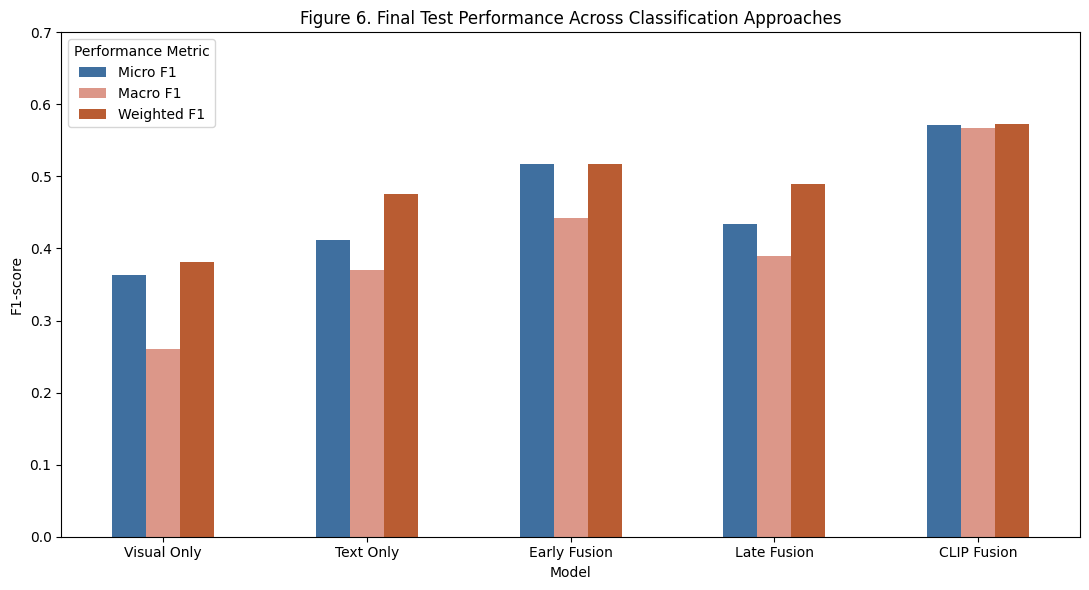

In [90]:
# 7.1 Visualise overall test-set model performance

comparison_metrics = [
    "Micro F1",
    "Macro F1",
    "Weighted F1"
]

comparison_plot_df = (
    final_test_results_df
    .set_index("Model")[
        comparison_metrics
    ]
)

ax = comparison_plot_df.plot(
    kind="bar",
    figsize=(11, 6),
    color=[
        "#3f6f9f",
        "#dc9789",
        "#b95c32"
    ]
)

ax.set_title(
    "Figure 6. Final Test Performance Across Classification Approaches"
)

ax.set_xlabel(
    "Model"
)

ax.set_ylabel(
    "F1-score"
)

ax.set_ylim(
    0,
    0.7
)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Performance Metric"
)

plt.tight_layout()
plt.show()

### Overall Model Comparison

The final test results demonstrate a clear performance hierarchy across the modelling approaches. The text-only model outperformed the visual-only baseline. This confirms that plot summaries provide stronger standalone information for genre prediction.

Both conventional multimodal approaches improved upon the unimodal baselines. Early Fusion achieved substantially stronger performance than Late Fusion, suggesting that learning directly from the combined visual and textual feature space is more effective than combining independently generated prediction probabilities for this dataset.

CLIP Fusion achieved the strongest performance across Micro F1, Macro F1 and Weighted F1, while also producing the lowest Hamming loss. This provides evidence that multimodal representations learned in a shared image-text embedding space capture more useful cross-modal semantic information than the supplied precomputed VGG and textual features.

In [91]:
# 7.2 Calculating per-genre performance for CLIP Fusion

from sklearn.metrics import (
    precision_recall_fscore_support
)

clip_precision, \
clip_recall, \
clip_f1, \
clip_support = precision_recall_fscore_support(
    y_test,
    clip_test_pred,
    average=None,
    zero_division=0
)

clip_per_genre_df = pd.DataFrame({
    "Genre": genre_names,
    "Precision": clip_precision,
    "Recall": clip_recall,
    "F1-score": clip_f1,
    "Support": clip_support
})

clip_per_genre_df = (
    clip_per_genre_df
    .sort_values(
        "F1-score",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

display(
    clip_per_genre_df.round(4)
)

,Genre,Precision,Recall,F1-score,Support
0,Documentary,0.7806,0.8754,0.8253,313
1,Animation,0.7529,0.8533,0.8000,150
2,Western,0.7355,0.8396,0.7841,106
3,Sci-Fi,0.6567,0.8060,0.7237,299
4,Horror,0.7415,0.6995,0.7199,406
5,Action,0.6321,0.6867,0.6583,533
6,Sport,0.5290,0.8632,0.6560,95
7,War,0.5870,0.7214,0.6473,201
8,Family,0.6199,0.6720,0.6449,250
9,Comedy,0.8724,0.4880,0.6259,1289


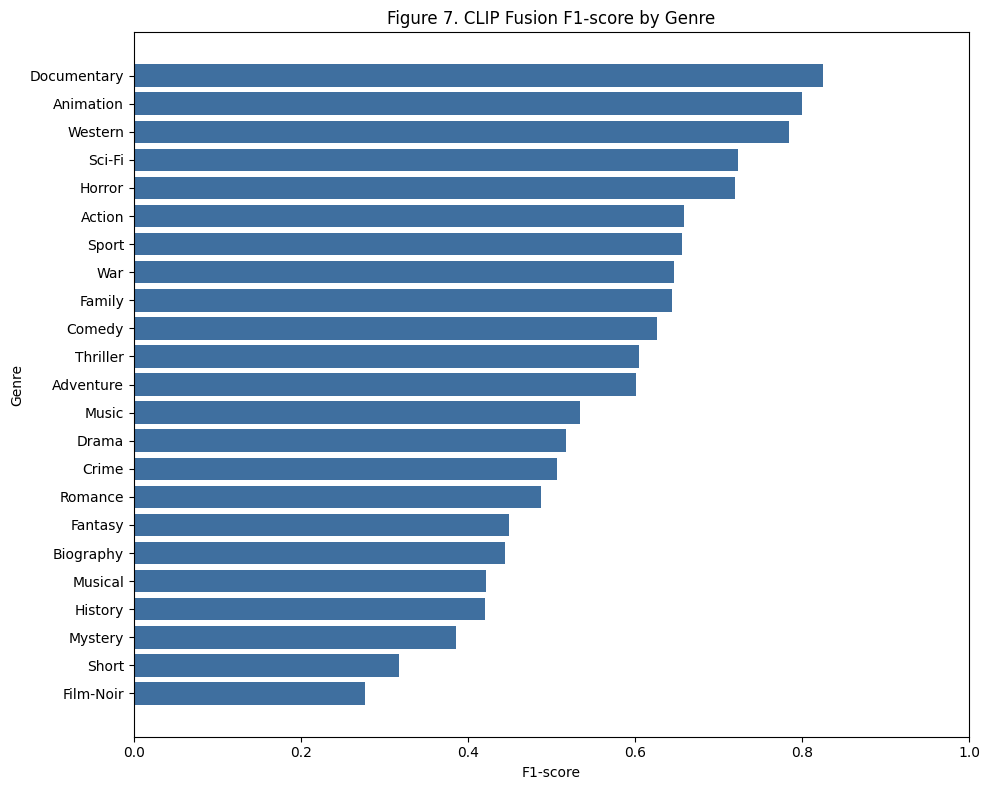

In [92]:
# Visualising CLIP Fusion performance by genre

genre_plot_df = (
    clip_per_genre_df
    .sort_values(
        "F1-score",
        ascending=True
    )
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    genre_plot_df[
        "Genre"
    ],
    genre_plot_df[
        "F1-score"
    ],
    color="#3f6f9f"
)

plt.title(
    "Figure 7. CLIP Fusion F1-score by Genre"
)

plt.xlabel(
    "F1-score"
)

plt.ylabel(
    "Genre"
)

plt.xlim(
    0,
    1
)

plt.tight_layout()
plt.show()

In [93]:
# 7.3 Identify strongest and weakest genre predictions

strongest_genres = (
    clip_per_genre_df
    .head(5)
)

weakest_genres = (
    clip_per_genre_df
    .tail(5)
    .sort_values(
        "F1-score"
    )
)

print(
    "Five strongest genres:"
)

display(
    strongest_genres.round(4)
)

print(
    "\nFive weakest genres:"
)

display(
    weakest_genres.round(4)
)

Five strongest genres:


,Genre,Precision,Recall,F1-score,Support
0,Documentary,0.7806,0.8754,0.8253,313
1,Animation,0.7529,0.8533,0.8000,150
2,Western,0.7355,0.8396,0.7841,106
3,Sci-Fi,0.6567,0.8060,0.7237,299
4,Horror,0.7415,0.6995,0.7199,406



Five weakest genres:


,Genre,Precision,Recall,F1-score,Support
22,Film-Noir,0.1667,0.8235,0.2772,51
21,Short,0.2078,0.6761,0.3179,71
20,Mystery,0.3687,0.4045,0.3858,309
19,History,0.3459,0.5349,0.4201,172
18,Musical,0.3162,0.6349,0.4222,126


In [94]:
# 7.4 Evaluate fusion models using their selected validation thresholds

early_val_pred_optimised = (
    early_val_prob
    >= BEST_EARLY_THRESHOLD
).astype(int)

late_val_pred_optimised = (
    late_val_prob
    >= BEST_LATE_THRESHOLD
).astype(int)

clip_val_pred_optimised = (
    clip_val_prob
    >= BEST_CLIP_THRESHOLD
).astype(int)


early_val_final = evaluate_multilabel_model(
    y_val,
    early_val_pred_optimised,
    "Early Fusion"
)

late_val_final = evaluate_multilabel_model(
    y_val,
    late_val_pred_optimised,
    "Late Fusion"
)

clip_val_final = evaluate_multilabel_model(
    y_val,
    clip_val_pred_optimised,
    "CLIP Fusion"
)

In [95]:
# Compare validation and test Macro F1

validation_macro = {
    "Early Fusion": early_val_final[
        "Macro F1"
    ],
    "Late Fusion": late_val_final[
        "Macro F1"
    ],
    "CLIP Fusion": clip_val_final[
        "Macro F1"
    ]
}

test_macro = (
    final_test_results_df
    .set_index("Model")[
        "Macro F1"
    ]
)

generalisation_rows = []

for model_name in [
    "Early Fusion",
    "Late Fusion",
    "CLIP Fusion"
]:

    val_score = validation_macro[
        model_name
    ]

    test_score = test_macro[
        model_name
    ]

    generalisation_rows.append({
        "Model": model_name,
        "Validation Macro F1": val_score,
        "Test Macro F1": test_score,
        "Absolute Gap": abs(
            val_score - test_score
        )
    })

generalisation_df = pd.DataFrame(
    generalisation_rows
)

display(
    generalisation_df.round(4)
)

,Model,Validation Macro F1,Test Macro F1,Absolute Gap
0,Early Fusion,0.4340,0.4419,0.0079
1,Late Fusion,0.3887,0.3891,0.0005
2,CLIP Fusion,0.5676,0.5676,0.0000


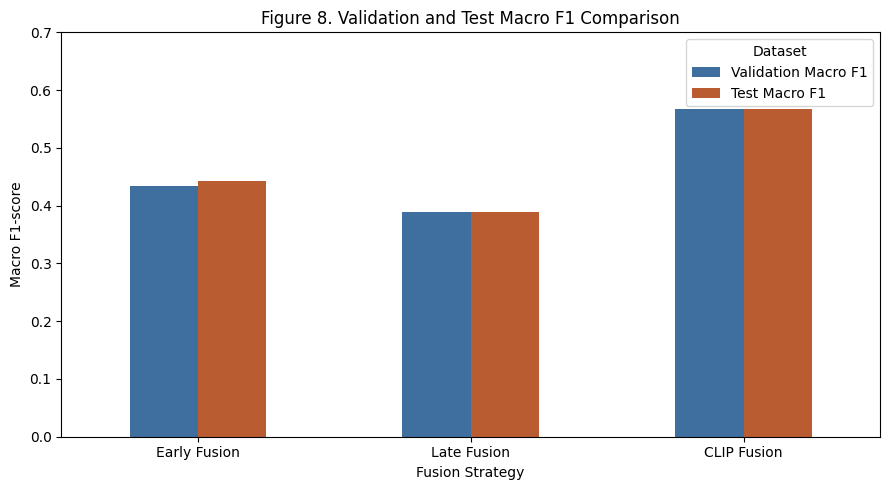

In [96]:
# visualising validation and test Macro F1

generalisation_plot_df = (
    generalisation_df
    .set_index("Model")[
        [
            "Validation Macro F1",
            "Test Macro F1"
        ]
    ]
)

ax = generalisation_plot_df.plot(
    kind="bar",
    figsize=(9, 5),
    color=[
        "#3f6f9f",
        "#b95c32"
    ]
)

ax.set_title(
    "Figure 8. Validation and Test Macro F1 Comparison"
)

ax.set_xlabel(
    "Fusion Strategy"
)

ax.set_ylabel(
    "Macro F1-score"
)

ax.set_ylim(
    0,
    0.7
)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Dataset"
)

plt.tight_layout()
plt.show()

In [97]:
# 7.5 calculating per-genre error rates for CLIP Fusion

genre_error_rows = []

for index, genre in enumerate(
    genre_names
):

    true_values = y_test[
        :,
        index
    ]

    predicted_values = clip_test_pred[
        :,
        index
    ]

    errors = np.sum(
        true_values != predicted_values
    )

    error_rate = (
        errors
        /
        len(
            true_values
        )
    )

    genre_error_rows.append({
        "Genre": genre,
        "Support": int(
            np.sum(
                true_values
            )
        ),
        "Errors": int(
            errors
        ),
        "Error Rate": error_rate
    })


genre_error_df = pd.DataFrame(
    genre_error_rows
)

genre_error_df = (
    genre_error_df
    .sort_values(
        "Error Rate",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

display(
    genre_error_df.round(4)
)

,Genre,Support,Errors,Error Rate
0,Drama,2095,1412,0.3618
1,Comedy,1289,752,0.1927
2,Romance,805,667,0.1709
3,Thriller,779,563,0.1442
4,Crime,576,471,0.1207
5,Mystery,309,398,0.1020
6,Action,533,380,0.0974
7,Adventure,407,315,0.0807
8,Fantasy,290,314,0.0805
9,History,172,254,0.0651


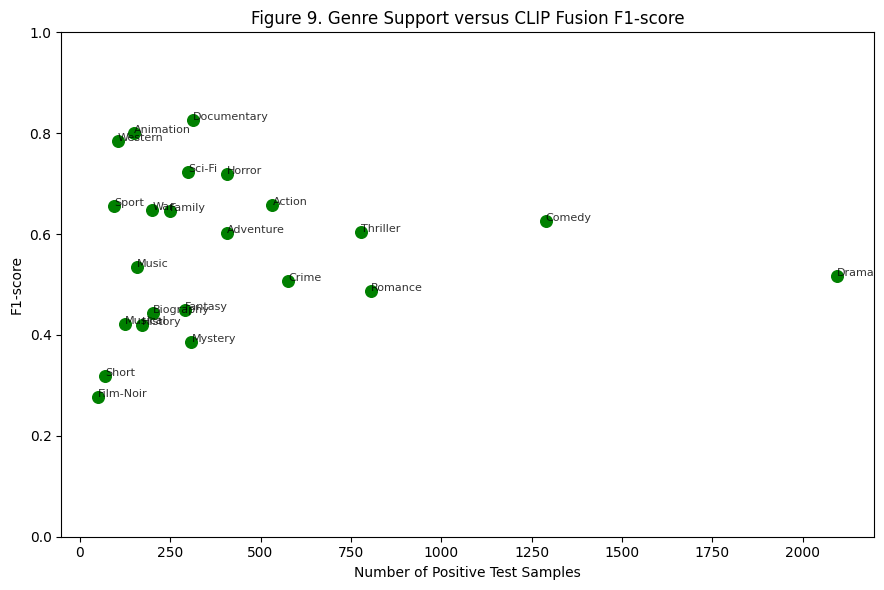

In [98]:
# visualising support against genre-level F1-score

genre_analysis_df = (
    clip_per_genre_df[
        [
            "Genre",
            "Support",
            "F1-score"
        ]
    ]
)

plt.figure(
    figsize=(9, 6)
)

plt.scatter(
    genre_analysis_df[
        "Support"
    ],
    genre_analysis_df[
        "F1-score"
    ],
    color="#008000",
    s=70
)

for _, row in genre_analysis_df.iterrows():

    plt.annotate(
        row[
            "Genre"
        ],
        (
            row[
                "Support"
            ],
            row[
                "F1-score"
            ]
        ),
        fontsize=8,
        alpha=0.8
    )

plt.title(
    "Figure 9. Genre Support versus CLIP Fusion F1-score"
)

plt.xlabel(
    "Number of Positive Test Samples"
)

plt.ylabel(
    "F1-score"
)

plt.ylim(
    0,
    1
)

plt.tight_layout()
plt.show()

## 7. Final Evaluation and Error Analysis

### Overall Model Comparison

The final held-out test evaluation demonstrates a clear advantage for multimodal learning over the unimodal baselines. The visual-only model produced the weakest performance, with a Micro F1-score of 0.3636 and Macro F1-score of 0.2606. The text-only model improved these scores to 0.4115 and 0.3708 respectively. This indicates that plot summaries contain stronger standalone genre information than movie posters.

Combining the two modalities further improved classification performance. Early Fusion achieved a Micro F1-score of 0.5166 and Macro F1-score of 0.4419, outperforming both unimodal models. Late Fusion produced smaller improvements, reaching a Macro F1-score of 0.3891.

The strongest approach was CLIP Fusion. Which achieved a Micro F1-score of 0.5719, Macro F1-score of 0.5676 and Weighted F1-score of 0.5733. It also obtained the lowest Hamming loss of 0.0848. The relatively similar Micro, Macro and Weighted F1-scores indicate that the CLIP-based representation provided comparatively balanced performance across both frequent and less frequent genres.

### Per-Genre Performance

CLIP Fusion showed substantial variation in predictive performance across the 23 genres. Documentary achieved the highest F1-score of 0.8253, followed by Animation (0.8000), Western (0.7841), Sci-Fi (0.7237) and Horror (0.7199).

The weakest genres were Film-Noir (0.2772), Short (0.3179), Mystery (0.3858), History (0.4201) and Musical (0.4222). Film-Noir and Short showed particularly low precision despite relatively high recall, indicating that the classifier identified many relevant examples but also produced a large number of false-positive predictions for these rare classes.

Class frequency alone did not determine performance. For example, Western achieved an F1-score of 0.7841 with only 106 positive test samples, while Drama, the most frequent genre with 2,095 positive samples, achieved an F1-score of only 0.5171. Drama demonstrated very high precision (0.9119) but relatively low recall (0.3609), indicating that the classifier was conservative when assigning this broad genre.

These results suggest that genre distinctiveness and the semantic information available in posters and plot descriptions are important in addition to class frequency. Genres with visually or semantically distinctive patterns, such as Documentary, Animation, Western and Horror, were generally identified more effectively.

### Error Analysis

The largest overall number of label-level errors occurred for Drama, Comedy and Romance. This partly reflects their high prevalence in the test set, which creates more opportunities for both false-positive and false-negative predictions.

The error count for an individual genre represents all incorrect binary decisions for that label, including both false positives and false negatives. Consequently, the number of errors may exceed the number of positive examples for a genre.

The support-versus-F1 analysis shows that performance is not explained solely by label frequency. Although several low-support classes perform poorly, other relatively uncommon classes such as Western, Animation and Sport achieve strong F1-scores. This indicates that representational separability and cross-modal semantic cues also influence classification difficulty.

### Generalisation and Overfitting

The fusion models demonstrated stable generalisation from the validation partition to the held-out test set. Early Fusion obtained validation and test Macro F1-scores of 0.4340 and 0.4419 respectively, producing an absolute difference of only 0.0079. Late Fusion produced an even smaller difference of 0.0005.

CLIP Fusion demonstrated the strongest stability, obtaining a Macro F1-score of 0.5676 on both the validation and test partitions. This indicates no observable degradation on the held-out test data and provides evidence that the frozen CLIP representation combined with the linear classifier generalises effectively without substantial overfitting.

The evaluation supports CLIP Fusion as the preferred approach because it combines the highest classification performance, the lowest Hamming loss and highly stable validation-to-test generalisation.

# 8. Efficiency, Ethics, Limitations and Model Selection

The final model should not be selected solely from predictive accuracy. Computational cost, scalability, dataset limitations, potential bias and practical deployment considerations are also relevant when assessing a multimodal system.

In [99]:
# 8.1 Summarise model representation and computational characteristics

efficiency_df = pd.DataFrame({
    "Approach": [
        "Visual Only",
        "Text Only",
        "Early Fusion",
        "Late Fusion",
        "CLIP Fusion"
    ],

    "Feature Dimensions": [
        4083,
        300,
        4383,
        4383,
        1024
    ],

    "Representation": [
        "Precomputed VGG",
        "Precomputed Text",
        "VGG + Text Concatenation",
        "Separate VGG and Text Models",
        "CLIP Image + Text"
    ],

    "Additional Training": [
        "Linear Classifier",
        "Linear Classifier",
        "Linear Classifier",
        "Two Linear Classifiers",
        "Linear Classifier"
    ]
})

display(
    efficiency_df
)

,Approach,Feature Dimensions,Representation,Additional Training
0,Visual Only,4083,Precomputed VGG,Linear Classifier
1,Text Only,300,Precomputed Text,Linear Classifier
2,Early Fusion,4383,VGG + Text Concatenation,Linear Classifier
3,Late Fusion,4383,Separate VGG and Text Models,Two Linear Classifiers
4,CLIP Fusion,1024,CLIP Image + Text,Linear Classifier


### Efficiency Considerations

The supplied VGG and textual features provide computationally inexpensive representations because feature extraction has already been performed. The visual representation is comparatively high-dimensional at 4,083 retained features, while the textual representation contains only 300 dimensions.

Early Fusion produces the largest single representation at 4,383 dimensions. Late Fusion retains two separate classifiers and therefore introduces additional inference and model-management overhead.

CLIP Fusion requires the greatest initial feature-extraction cost because both movie posters and plot summaries must pass through pretrained neural encoders. However, the encoders are frozen and their resulting embeddings can be cached. Once extracted, the fused CLIP representation contains only 1,024 dimensions, substantially fewer than the conventional Early Fusion representation.

CLIP Fusion introduces a higher one-time preprocessing cost but provides a relatively compact representation for subsequent classifier training and inference.

### Ethics and Bias Assessment

The MM-IMDb dataset contains publicly available movie-related content rather than sensitive personal records, reducing many privacy risks associated with multimodal datasets containing biometric, medical or behavioural information. Nevertheless, several ethical and bias considerations remain relevant.

The genre distribution is strongly imbalanced. Drama and Comedy occur substantially more frequently than classes such as Film-Noir, Short and Sport. Although threshold optimisation and class-weighted classifiers reduce some of the effects of imbalance, performance remains uneven across genres.

The dataset may also reflect historical and cultural biases within IMDb and the film industry. Representation of particular countries, languages, time periods, production styles and demographic groups may be uneven. As a result, model performance should not be assumed to generalise equally to films outside the distribution represented in MM-IMDb.

The use of pretrained CLIP representations introduces an additional source of potential bias because the encoder inherits patterns and associations from its large-scale pretraining data. Strong predictive performance therefore does not imply that its learned representations are culturally neutral or free from inappropriate associations.

The system is intended for movie-genre classification and should not be repurposed for high-stakes decisions involving individuals. Any real-world deployment should include continued monitoring for distribution shift, class-specific performance and unintended systematic errors.

### Limitations

Several limitations should be considered when interpreting the results.

*   Genre labels are inherently subjective and overlapping, meaning that some classification errors may represent ambiguous genre boundaries rather than completely incorrect predictions.
*   The dataset is strongly imbalanced across the 23 genres.
*   The supplied textual representation and decoded plot summaries originate from an existing preprocessed dataset rather than newly collected raw IMDb content.
*   CLIP text inputs are restricted by the model's context length, meaning that long movie plots are truncated during feature extraction.
*   The pretrained CLIP encoders were not fine-tuned on MM-IMDb because of computational and time constraints.
*   A single global decision threshold was selected for each model. Genre-specific thresholds could potentially improve minority-class performance.
*   Evaluation was performed using one fixed train-validation-test split rather than repeated cross-validation because of the computational cost of multimodal feature extraction.

### Final Model Selection

CLIP Fusion is selected as the most appropriate final approach.

It achieved the highest test-set Micro F1-score (0.5719), Macro F1-score (0.5676) and Weighted F1-score (0.5733), while also producing the lowest Hamming loss (0.0848). The model improved both overall classification quality and class-balanced performance compared with the unimodal baselines and conventional fusion approaches.

Its validation and test Macro F1-scores were both 0.5676. This provides strong evidence of stable generalisation. The model also uses a comparatively compact 1,024-dimensional fused representation once the pretrained CLIP embeddings have been extracted and cached.

Early Fusion remains a useful computationally simpler alternative and  outperformed the unimodal models. So, its Macro F1-score of 0.4419 was considerably below that of CLIP Fusion. Late Fusion provided only modest improvements over the text-only baseline.

The results support the use of pretrained multimodal representations that  align visual and textual semantics rather than relying only on independent legacy feature spaces.

# 9. Conclusion and Future Work

### Conclusion

This project investigated multi-label movie genre classification using the MM-IMDb dataset by combining textual plot information and visual movie-poster information.

The experiments showed that multimodal learning improved upon unimodal baselines. Among the conventional approaches, Early Fusion performed better than Late Fusion. This indicated that jointly learning from the combined visual and textual feature space was more effective than combining independent prediction probabilities.

The strongest approach was CLIP Fusion, which achieved a test Micro F1-score of 0.5719, Macro F1-score of 0.5676 and Weighted F1-score of 0.5733, together with the lowest Hamming loss of 0.0848. Its validation and test Macro F1-scores were also identical at 0.5676, indicating stable generalisation with no substantial evidence of overfitting.

The results demonstrate that using pretrained image-text representations within a shared semantic embedding space provides a clear advantage for multimodal genre classification compared with the supplied VGG and textual representations.

### Future Work

Several extensions could be explored to further improve the system:

*   fine-tuning the CLIP encoders on MM-IMDb rather than using frozen pretrained representations,
*   optimising separate decision thresholds for individual genres rather than using one global threshold,
*   investigating attention-based or cross-modal fusion architectures that learn interactions between poster and plot embeddings,
*   applying stronger imbalance-handling strategies for rare genres like Film-Noir and Short,
*   evaluating alternative pretrained multimodal models and comparing them with CLIP,
*   performing repeated or cross-validated evaluation to further assess model stability,
*   analysing explainability, like identifying which textual content or poster regions contribute most strongly to genre predictions,
*   evaluating the approach on newer or more diverse movie datasets to assess robustness to distribution shift.